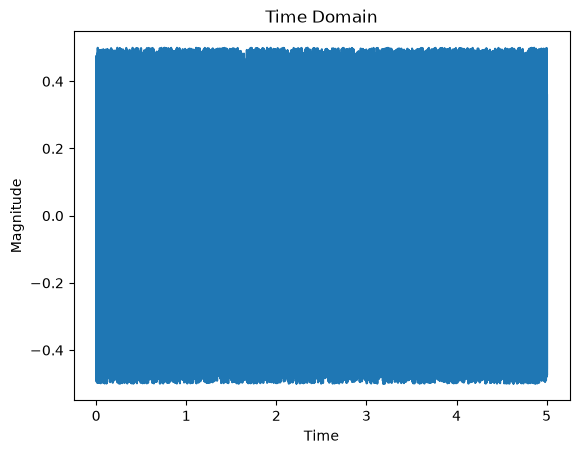

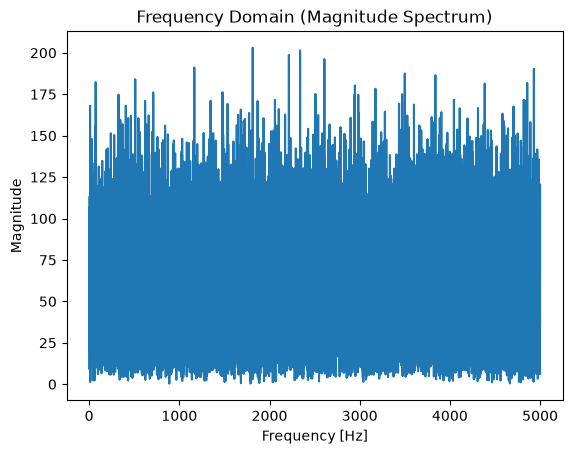

In [1]:
#
#
#
import numpy as np
import matplotlib.pyplot as plt
import arslabrobotics as ar

delta_t = 1e-4  # Sampling interval

signal = []

# generate a random signal
tm = ar.utils.Time(use_fake_time = True)
tm.start()
while tm.get() < 5:
    tm.sleep(delta_t)
    tm.elapsed()
    val = np.random.uniform(0,1) - 0.5
    signal.append(val)

# Compute FFT
fft_values = np.fft.fft(signal)
N = len(signal)

# Compute frequency bins
freq = np.fft.fftfreq(N, delta_t)

# Take the magnitude (absolute value) of the FFT
magnitude = np.abs(fft_values)

n_samples = N
plt.plot(np.arange(n_samples) * delta_t, signal[:n_samples])
plt.title('Time Domain')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.show()

n_samples = N//2
plt.plot(freq[1:n_samples], magnitude[1:n_samples])
plt.title('Frequency Domain (Magnitude Spectrum)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()

[ 0.06745527  0.         -0.13491055  0.          0.06745527]
[ 1.         -1.94246878  2.1192024  -1.21665164  0.4128016 ]


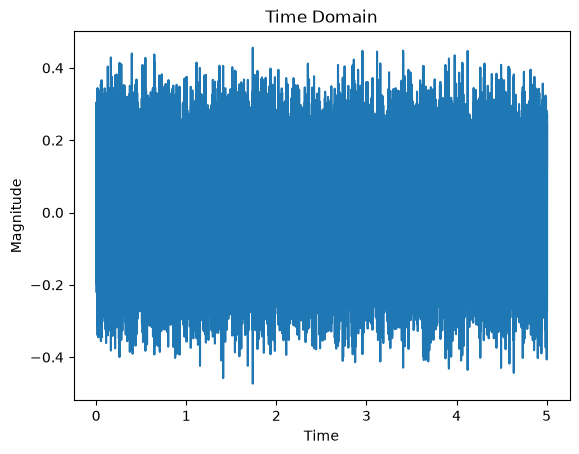

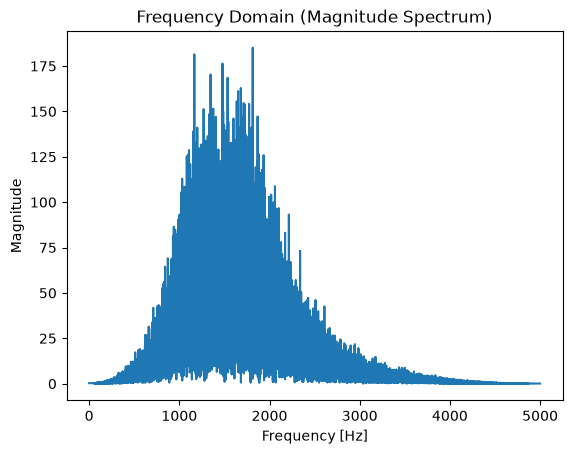

In [8]:

# apply filter
low_pass = ar.filters.ButterworthFilter(2, 'bandpass', [1000,2000], 1.0/delta_t)

filtered_signal = []
for v in signal:
    filtered_signal.append(low_pass.evaluate(v))

# Compute FFT
fft_values = np.fft.fft(filtered_signal)
N = len(filtered_signal)

# Compute frequency bins
freq = np.fft.fftfreq(N, delta_t)

# Take the magnitude (absolute value) of the FFT
magnitude = np.abs(fft_values)

n_samples = N
plt.plot(np.arange(n_samples) * delta_t, filtered_signal[:n_samples])
plt.title('Time Domain')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.show()

n_samples = N//2
plt.plot(freq[1:n_samples], magnitude[1:n_samples])
plt.title('Frequency Domain (Magnitude Spectrum)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()